In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
sys.path.insert(0, r"C:\Users\Noor Fatima\QuantCourseBP")

In [2]:
from src.market_data import MarketData
from src.enums import (
    Stock, PutCallFwd, LongShort, GreekMethod,
    FiniteDifferenceMethod, BumpSizeMethod
)
from src.model import BSVolModel
from src.contract import EuropeanContract
from src.numerical_method import Params
from src.pricer import EuropeanAnalyticPricer

QuantCourseBP 75e9c496a2c17a1114c1e8b6617fc4dca19876ab*


In [14]:
MarketData.initialize()
model = BSVolModel(Stock.BLUECHIP_BANK)
contract = EuropeanContract(
    Stock.BLUECHIP_BANK,
    PutCallFwd.CALL,
    LongShort.LONG,
    model.spot,
    1.0
)
pricer = EuropeanAnalyticPricer(contract, model, Params())
analytic_delta = pricer.calc_delta(GreekMethod.ANALYTIC)
analytic_gamma = pricer.calc_gamma(GreekMethod.ANALYTIC)

# Assignments - Numerical greeks

Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative. 

(a) Create two Enums to store the labels. Implement all combinations for delta and gamma calculation.

(b) Compare greeks using the analytic and the finite difference approximation on a set of European options. 

(c) Compare absolute and relative bumping and suggest optimal bump sizes. 

(d) Visualize the numerical error.

### (a) Create two Enums to store the labels. Implement all combinations for delta and gamma calculation.

In [4]:
for method in FiniteDifferenceMethod:
    for bump_method in BumpSizeMethod:
        pricer.finite_difference_method = method
        pricer.bump_size_method = bump_method
        pricer.bump_size = 0.01

        numerical_delta = pricer.calc_delta(GreekMethod.BUMP)
        numerical_gamma = pricer.calc_gamma(GreekMethod.BUMP)

        delta_error = abs(numerical_delta - analytic_delta)
        gamma_error = abs(numerical_gamma - analytic_gamma)

        print(f"\nMethod: {method.value}, Bump: {bump_method.value}")
        print(f"Delta: {numerical_delta:.10f}, Error: {delta_error:.10e}")
        print(f"Gamma: {numerical_gamma:.10f}, Error: {gamma_error:.10e}")


Method: FORWARD, Bump: ABSOLUTE
Delta: 0.6262009372, Error: 3.8207069990e-05
Gamma: 0.0076406919, Error: 1.0830415113e-06

Method: FORWARD, Bump: RELATIVE
Delta: 0.6311057304, Error: 4.9430002958e-03
Gamma: 0.0075001414, Error: 1.4163359319e-04

Method: BACKWARD, Bump: ABSOLUTE
Delta: 0.6261245194, Error: 3.8210681426e-05
Gamma: 0.0076428575, Error: 1.0825506387e-06

Method: BACKWARD, Bump: RELATIVE
Delta: 0.6211585686, Error: 5.0041615714e-03
Gamma: 0.0077819373, Error: 1.4016235760e-04

Method: CENTRAL, Bump: ABSOLUTE
Delta: 0.6261627283, Error: 1.8057181306e-09
Gamma: 0.0076417751, Error: 1.8088932088e-10

Method: CENTRAL, Bump: RELATIVE
Delta: 0.6261321495, Error: 3.0580637790e-05
Gamma: 0.0076416700, Error: 1.0493895431e-07


### (b) Compare greeks using the analytic and the finite difference approximation on a set of European options. 

In [ ]:
test_options = []

for strike_factor in [0.9, 1.0, 1.1]:
    for option_type in [PutCallFwd.CALL, PutCallFwd.PUT]:
        contract_test = EuropeanContract(
            Stock.BLUECHIP_BANK,
            option_type,
            LongShort.LONG,
            model.spot * strike_factor,
            1.0
        )

        test_options.append(contract_test)

comparison_results = []

for contract_test in test_options:
    test_pricer = EuropeanAnalyticPricer(
        contract_test, model, Params()
    )

    ad = test_pricer.calc_delta(GreekMethod.ANALYTIC)
    ag = test_pricer.calc_gamma(GreekMethod.ANALYTIC)

    for method in FiniteDifferenceMethod:
        test_pricer.finite_difference_method = method
        test_pricer.bump_size_method = BumpSizeMethod.ABSOLUTE
        test_pricer.bump_size = 0.01

        nd = test_pricer.calc_delta(GreekMethod.BUMP)
        ng = test_pricer.calc_gamma(GreekMethod.BUMP)

        comparison_results.append({
            "Option": contract_test.derivative_type.value,
            "Strike": contract_test.strike,
            "Method": method.value,
            "Analytical Delta": ad,
            "Numerical Delta": nd,
            "Delta Error": abs(ad - nd),
            "Analytical Gamma": ag,
            "Numerical Gamma": ng,
            "Gamma Error": abs(ag - ng)
        })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(10))

,Option,Strike,Method,Analytical Delta,Numerical Delta,Delta Error,Analytical Gamma,Numerical Gamma,Gamma Error
0,CALL,117.153,FORWARD,0.725203,0.725236,3.364040e-05,0.006729,0.006727,1.328700e-06
1,CALL,117.153,BACKWARD,0.725203,0.725169,3.364480e-05,0.006729,0.006730,1.328600e-06
2,CALL,117.153,CENTRAL,0.725203,0.725203,2.200000e-09,0.006729,0.006729,2.000000e-10
3,PUT,117.153,FORWARD,-0.274797,-0.274764,3.364040e-05,0.006729,0.006727,1.328900e-06
4,PUT,117.153,BACKWARD,-0.274797,-0.274831,3.364480e-05,0.006729,0.006730,1.329200e-06
5,PUT,117.153,CENTRAL,-0.274797,-0.274797,2.200000e-09,0.006729,0.006729,1.000000e-10
6,CALL,130.170,FORWARD,0.626163,0.626201,3.820710e-05,0.007642,0.007641,1.083000e-06
7,CALL,130.170,BACKWARD,0.626163,0.626125,3.821070e-05,0.007642,0.007643,1.082600e-06
8,CALL,130.170,CENTRAL,0.626163,0.626163,1.800000e-09,0.007642,0.007642,2.000000e-10
9,PUT,130.170,FORWARD,-0.373837,-0.373799,3.820710e-05,0.007642,0.007641,1.082900e-06


### (c) Compare absolute and relative bumping and suggest optimal bump sizes. 

In [6]:
fine_bump_sizes = np.logspace(-8, -1, 50)
fine_results = []

for method in FiniteDifferenceMethod:
    for bump_method in BumpSizeMethod:
        pricer.finite_difference_method = method
        pricer.bump_size_method = bump_method

        for h in fine_bump_sizes:
            pricer.bump_size = h

            nd = pricer.calc_delta(GreekMethod.BUMP)
            ng = pricer.calc_gamma(GreekMethod.BUMP)

            fine_results.append({
                "Method": method.value,
                "Bump type": bump_method.value,
                "Bump size": h,
                "Delta error": abs(nd - analytic_delta),
                "Gamma error": abs(ng - analytic_gamma)
            })

fine_df = pd.DataFrame(fine_results)

print("Refined optimal bump sizes:")
for error in ["Delta error", "Gamma error"]:
    print(f"\n{error}:")
    best = fine_df.loc[
        fine_df.groupby(["Method", "Bump type"])[error].idxmin(),
        ["Method", "Bump type", "Bump size", error]
    ]
    print(best.to_string(index=False))

Refined optimal bump sizes:

Delta error:
  Method Bump type    Bump size  Delta error
BACKWARD  ABSOLUTE 7.196857e-07 5.680374e-09
BACKWARD  RELATIVE 1.000000e-08 3.765863e-09
 CENTRAL  ABSOLUTE 5.179475e-04 2.203904e-12
 CENTRAL  RELATIVE 1.000000e-06 5.535572e-13
 FORWARD  ABSOLUTE 1.389495e-06 6.436404e-10
 FORWARD  RELATIVE 1.389495e-08 9.765127e-09

Gamma error:
  Method Bump type  Bump size  Gamma error
BACKWARD  ABSOLUTE   0.000720 5.040545e-08
BACKWARD  RELATIVE   0.000003 5.101242e-08
 CENTRAL  ABSOLUTE   0.019307 8.434694e-12
 CENTRAL  RELATIVE   0.000139 9.171189e-12
 FORWARD  ABSOLUTE   0.000518 1.848797e-08
 FORWARD  RELATIVE   0.000003 7.254967e-09


The optimal bump size differs between Delta and Gamma and also depends on the finite difference method. Absolute bumping uses a fixed change in the underlying price, whereas relative bumping scales the change according to the current spot price. Relative bumping can therefore be more suitable when comparing options.

In our experiments, central differences generally achieve the smallest numerical errors. The optimal bump size should be selected by balancing truncation and floating-point round-off errors.

### (d) Visualize the numerical error

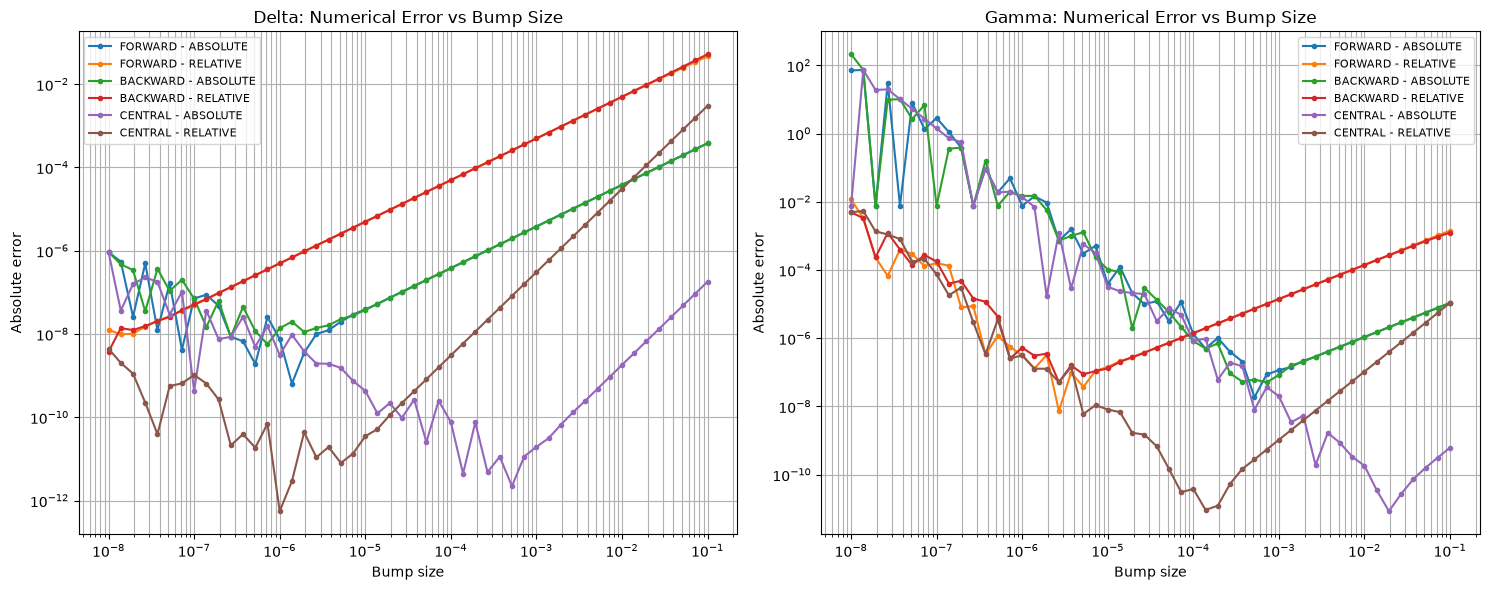

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for method in FiniteDifferenceMethod:
    for bump_method in BumpSizeMethod:
        subset = fine_df[
            (fine_df["Method"] == method.value) &
            (fine_df["Bump type"] == bump_method.value)
        ]

        label = f"{method.value} - {bump_method.value}"

        axes[0].loglog(
            subset["Bump size"],
            subset["Delta error"],
            marker="o",
            markersize=3,
            label=label
        )

        axes[1].loglog(
            subset["Bump size"],
            subset["Gamma error"],
            marker="o",
            markersize=3,
            label=label
        )

axes[0].set_title("Delta: Numerical Error vs Bump Size")
axes[0].set_xlabel("Bump size")
axes[0].set_ylabel("Absolute error")
axes[0].grid(True, which="both")
axes[0].legend(fontsize=8)

axes[1].set_title("Gamma: Numerical Error vs Bump Size")
axes[1].set_xlabel("Bump size")
axes[1].set_ylabel("Absolute error")
axes[1].grid(True, which="both")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


Forward and backward finite differences generally have first-order truncation error, whereas central differences have second-order truncation error.

In our experiments, central differences provide the highest accuracy for both Delta and Gamma. When the bump size is too large, truncation error dominates. When it is too small, floating-point round-off errors become significant.

Therefore, the optimal bump size balances truncation and round-off errors.

# Projects:

Suppose $S_1(t)$ and $S_2(t)$ are independent stock processes with equal volatility. $S_1(0)=S_2(0)=100.$
The contract at maturity pays the value of the most expensive stock: $V(T)=\max_i\{S_1(T),S_2(T)\}.$
* What is the formula for the fair value of the contract, $V(0)$?         
* Derive the partial differential equation for this contract              
* Solve the resultant PDE using Finite Difference Method                   
* Compare the results obtained through solving the PDE with Monte Carlo Method  

In [8]:
S10 = 100.0
S20 = 100.0
r = 0.05
sigma = 0.20
T = 1.0
S_max = 2 * max(S10, S20)

#### What is the formula for the fair value of the contract, $V(0)$?

Consider two independent stock processes under the risk-neutral measure:

$dS_i(t)=rS_i(t)\,dt+\sigma S_i(t)\,dW_i(t),
\qquad i=1,2.$

The contract pays the maximum of the two stock prices at maturity:

$V(T)=\max(S_1(T),S_2(T)).$

Since both stocks have equal initial prices $S_0=100$ and equal volatility, the analytical fair value is

$V(0)=2S_0\Phi\left(\sigma\sqrt{\frac{T}{2}}\right)$

where $\Phi$ is the standard normal cumulative distribution function.

For the given parameters:

$V(0)=111.246292$.


In [9]:
V_analytical = 2 * S10 * norm.cdf(sigma * np.sqrt(T / 2))

print(f"Analytical fair value: {V_analytical:.6f}")

Analytical fair value: 111.246292


#### Derive the partial differential equation for this contract              

Let $V=V(S_1,S_2,t)$ denote the contract value.

Applying Itô's lemma and using the independence of the two Brownian motions, we obtain the two-dimensional Black–Scholes PDE:

$V_t+
\frac12\sigma^2S_1^2V_{S_1S_1}
+\frac12\sigma^2S_2^2V_{S_2S_2}
+rS_1V_{S_1}
+rS_2V_{S_2}
-rV=0.$

The terminal condition is

$V(S_1,S_2,T)=\max(S_1,S_2).$

In [10]:
N_S = 100
N_t = 1000

S1 = np.linspace(0, S_max, N_S + 1)
S2 = np.linspace(0, S_max, N_S + 1)

dS1 = S1[1] - S1[0]
dS2 = S2[1] - S2[0]
dt = T / N_t

V_terminal = np.maximum(S1[:, None], S2[None, :])

print("Grid shape:", V_terminal.shape)
print("Terminal payoff at (100, 100):", V_terminal[50, 50])

Grid shape: (101, 101)
Terminal payoff at (100, 100): 100.0


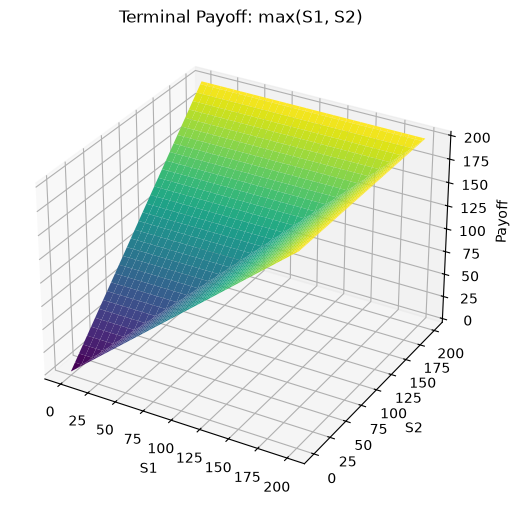

In [11]:
S1_grid, S2_grid = np.meshgrid(S1, S2, indexing="ij")

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S1_grid, S2_grid, V_terminal, cmap="viridis")

ax.set_xlabel("S1")
ax.set_ylabel("S2")
ax.set_zlabel("Payoff")
ax.set_title("Terminal Payoff: max(S1, S2)")

plt.show()

#### Solve the resultant PDE using Finite Difference Method                   

We transform the PDE using $\tau=T-t$ and solve it forward in time to maturity:

$V_\tau=
\frac12\sigma^2S_1^2V_{S_1S_1}
+\frac12\sigma^2S_2^2V_{S_2S_2}
+rS_1V_{S_1}
+rS_2V_{S_2}
-rV.$

We use an explicit Euler time-stepping scheme and central finite differences for the spatial derivatives. Analytical boundary values are used at the upper boundaries to reduce truncation error.

In [12]:
def upper_boundary(S_fixed, S_other, tau):

    if tau <= 0:
        return np.maximum(S_fixed, S_other)

    S_other = np.asarray(S_other)
    result = np.empty_like(S_other, dtype=float)

    zero_mask = S_other <= 0
    positive_mask = ~zero_mask

    result[zero_mask] = S_fixed

    vol = sigma * np.sqrt(2 * tau)

    d1 = (
        np.log(S_fixed / S_other[positive_mask])
        + sigma**2 * tau
    ) / vol

    d2 = d1 - vol

    result[positive_mask] = (
        S_fixed * norm.cdf(d1)
        + S_other[positive_mask] * norm.cdf(-d2)
    )

    return result


def solve_fd(N_S, N_t):

    S1 = np.linspace(0, S_max, N_S + 1)
    S2 = np.linspace(0, S_max, N_S + 1)

    dS1 = S1[1] - S1[0]
    dS2 = S2[1] - S2[0]
    dt = T / N_t

    V_old = np.maximum(S1[:, None], S2[None, :])

    for n in range(N_t):

        V_new = V_old.copy()

        for i in range(1, N_S):
            for j in range(1, N_S):

                dV_dS1 = (
                    V_old[i+1, j] - V_old[i-1, j]
                ) / (2*dS1)

                dV_dS2 = (
                    V_old[i, j+1] - V_old[i, j-1]
                ) / (2*dS2)

                d2V_dS1 = (
                    V_old[i+1, j] - 2*V_old[i, j]
                    + V_old[i-1, j]
                ) / dS1**2

                d2V_dS2 = (
                    V_old[i, j+1] - 2*V_old[i, j]
                    + V_old[i, j-1]
                ) / dS2**2

                V_new[i, j] = V_old[i, j] + dt * (
                    0.5*sigma**2*S1[i]**2*d2V_dS1
                    + 0.5*sigma**2*S2[j]**2*d2V_dS2
                    + r*S1[i]*dV_dS1
                    + r*S2[j]*dV_dS2
                    - r*V_old[i, j]
                )

        V_new[0, :] = S2
        V_new[:, 0] = S1

        tau = (n + 1) * dt

        V_new[-1, :] = upper_boundary(S_max, S2, tau)
        V_new[:, -1] = upper_boundary(S_max, S1, tau)

        V_old = V_new

    i0 = np.argmin(np.abs(S1 - S10))
    j0 = np.argmin(np.abs(S2 - S20))

    return V_old[i0, j0]

#### Compare the results obtained through solving the PDE with Monte Carlo Method  

We examine the convergence of the finite difference method by increasing the spatial grid size and the number of time steps. The absolute error is calculated as

Absolute Error=$
|V_{\mathrm{FD}}-V_{\mathrm{analytical}}|$.

We also estimate the contract value using one million Monte Carlo simulations of the two independent stock prices under the risk-neutral measure. A 95% confidence interval is calculated for the Monte Carlo estimate.

In [22]:
grid_sizes = [50, 100, 150]
time_steps = [500, 1000, 2000]

results = []

for N, Nt in zip(grid_sizes, time_steps):

    price = solve_fd(N, Nt)

    results.append({
        "Space points": N,
        "Time steps": Nt,
        "FD price": price,
        "Absolute error": abs(price - V_analytical)
    })

convergence_df = pd.DataFrame(results)
display(convergence_df.round(6))


,Space points,Time steps,FD price,Absolute error
0,50,500,111.220292,0.026000
1,100,1000,111.240522,0.005770
2,150,2000,111.243807,0.002484


In [23]:
np.random.seed(42)

M = 1_000_000

Z1 = np.random.standard_normal(M)
Z2 = np.random.standard_normal(M)

S1_T = S10 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z1
)

S2_T = S20 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z2
)
payoff = np.maximum(S1_T, S2_T)
discounted_payoff = np.exp(-r * T) * payoff

V_monte_carlo = np.mean(discounted_payoff)

MC_std_error = (
    np.std(discounted_payoff, ddof=1) / np.sqrt(M)
)

CI_lower = V_monte_carlo - 1.96 * MC_std_error
CI_upper = V_monte_carlo + 1.96 * MC_std_error

print(f"Monte Carlo price: {V_monte_carlo:.6f}")
print(f"Standard error:    {MC_std_error:.6f}")
print(f"95% confidence interval: [{CI_lower:.6f}, {CI_upper:.6f}]")

Monte Carlo price: 111.232421
Standard error:    0.018730
95% confidence interval: [111.195710, 111.269132]


In [24]:
finest_fd_price = convergence_df.iloc[-1]["FD price"]

comparison_df = pd.DataFrame({
    "Method": ["Analytical", "Finite Difference", "Monte Carlo"],
    "Price": [
        V_analytical,
        finest_fd_price,
        V_monte_carlo
    ],
    "Absolute error": [
        0,
        abs(finest_fd_price - V_analytical),
        abs(V_monte_carlo - V_analytical)
    ]
})

display(comparison_df.round(6))

print(
    f"Monte Carlo 95% confidence interval: "
    f"[{CI_lower:.6f}, {CI_upper:.6f}]"
)

,Method,Price,Absolute error
0,Analytical,111.246292,0.000000
1,Finite Difference,111.243807,0.002484
2,Monte Carlo,111.232421,0.013870


Monte Carlo 95% confidence interval: [111.195710, 111.269132]
